In [1]:
import os
for var in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ[var] = "8"
import sys, random, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED)
PROJECT_ROOT = Path("/workspace/sic_final_project")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
%%writefile -a /workspace/sic_final_project/src/data_processing.py


# ---------------- Phase 3: integrity, duplicates ----------------
import hashlib
import numpy as np
import imagehash
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components


def inspect_image(path) -> dict:
    """FULLY decode one image. Returns integrity status, content hashes and
    32x32 grayscale statistics. Never raises: failures are recorded, not hidden."""
    rec = {"path": str(path), "decode_ok": False, "decode_error": None,
           "md5": None, "phash": None, "thumb_std": None, "thumb_mean": None}
    try:
        rec["md5"] = hashlib.md5(Path(path).read_bytes()).hexdigest()   # exact-duplicate fingerprint
        with Image.open(path) as img:
            img.load()                       # force the full pixel decode (catches truncated files)
            rgb = img.convert("RGB")         # standardise P / L / CMYK / RGBA -> RGB
        rec["phash"] = str(imagehash.phash(rgb))   # perceptual fingerprint (near-duplicates)
        thumb = np.asarray(rgb.convert("L").resize((32, 32)), dtype=np.float32)
        rec["thumb_std"], rec["thumb_mean"] = float(thumb.std()), float(thumb.mean())
        rec["decode_ok"] = True
    except Exception as exc:
        rec["decode_error"] = f"{type(exc).__name__}: {exc}"[:120]
    return rec


POPCOUNT = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)


def near_duplicate_pairs(hex_hashes, max_distance=4, chunk=256):
    """All index pairs (i<j) whose 64-bit perceptual hashes differ in <= max_distance bits."""
    H = np.array([np.frombuffer(bytes.fromhex(h), dtype=np.uint8) for h in hex_hashes])
    pairs = []
    for start in range(0, len(H), chunk):
        block = H[start:start + chunk]
        dist = POPCOUNT[block[:, None, :] ^ H[None, :, :]].sum(axis=2, dtype=np.uint16)
        rows, cols = np.nonzero(dist <= max_distance)
        rows = rows + start
        keep = cols > rows
        pairs.append(np.column_stack([rows[keep], cols[keep]]))
    return np.vstack(pairs)


def group_ids_from_pairs(n_items, pairs):
    """Connected components: items linked by near-duplicate pairs share a group id."""
    graph = csr_matrix((np.ones(len(pairs)), (pairs[:, 0], pairs[:, 1])), shape=(n_items, n_items))
    return connected_components(graph, directed=False)[1]

Appending to /workspace/sic_final_project/src/data_processing.py


In [3]:
import importlib, data_processing
importlib.reload(data_processing)

raw = pd.read_csv(PROJECT_ROOT / "data/metadata/metadata_raw.csv")
t0 = time.time()
with ThreadPoolExecutor(max_workers=8) as pool:
    integ = pd.DataFrame(list(tqdm(pool.map(data_processing.inspect_image, raw["path"]), total=len(raw))))
print(f"Inspected {len(integ):,} images in {time.time()-t0:.0f}s")

meta = raw.drop(columns=["error"]).merge(integ, on="path")
meta.to_csv(PROJECT_ROOT / "data/metadata/metadata_inspected.csv", index=False)

bad = meta[~meta["decode_ok"]]
print("\nQ16 - corrupted / unreadable files:", len(bad))
display(bad[["path", "label", "pil_format", "decode_error"]].head(20))

 96%|███████████████████████████████████████▏ | 23920/24998 [01:08<00:03, 354.63it/s]/usr/local/lib/python3.10/dist-packages/PIL/TiffImagePlugin.py:900: UserWarning: Truncated File Read
  warnings.warn(str(msg))
100%|█████████████████████████████████████████| 24998/24998 [01:11<00:00, 349.79it/s]


Inspected 24,998 images in 72s

Q16 - corrupted / unreadable files: 0


,path,label,pil_format,decode_error


In [4]:
mismatch = meta[(meta["extension"] == ".jpg") & (meta["pil_format"] != "JPEG")]
print("Files named .jpg but not JPEG inside:", len(mismatch))
print(pd.crosstab(mismatch["pil_format"], mismatch["label"]))

Files named .jpg but not JPEG inside: 229
label       Cat  Dog
pil_format          
BMP          71  102
GIF          22   29
PNG           0    4
PSD           1    0


Exact-duplicate files (in a group of 2+): 58 | extra copies: 30
Exact-duplicate groups with BOTH labels (label conflict): 2

Near-duplicate pairs: 39 (computed in 27s)
Images in a near-duplicate group: 70 | groups: 34 | largest group: 4
Near-duplicate groups with BOTH labels: 2


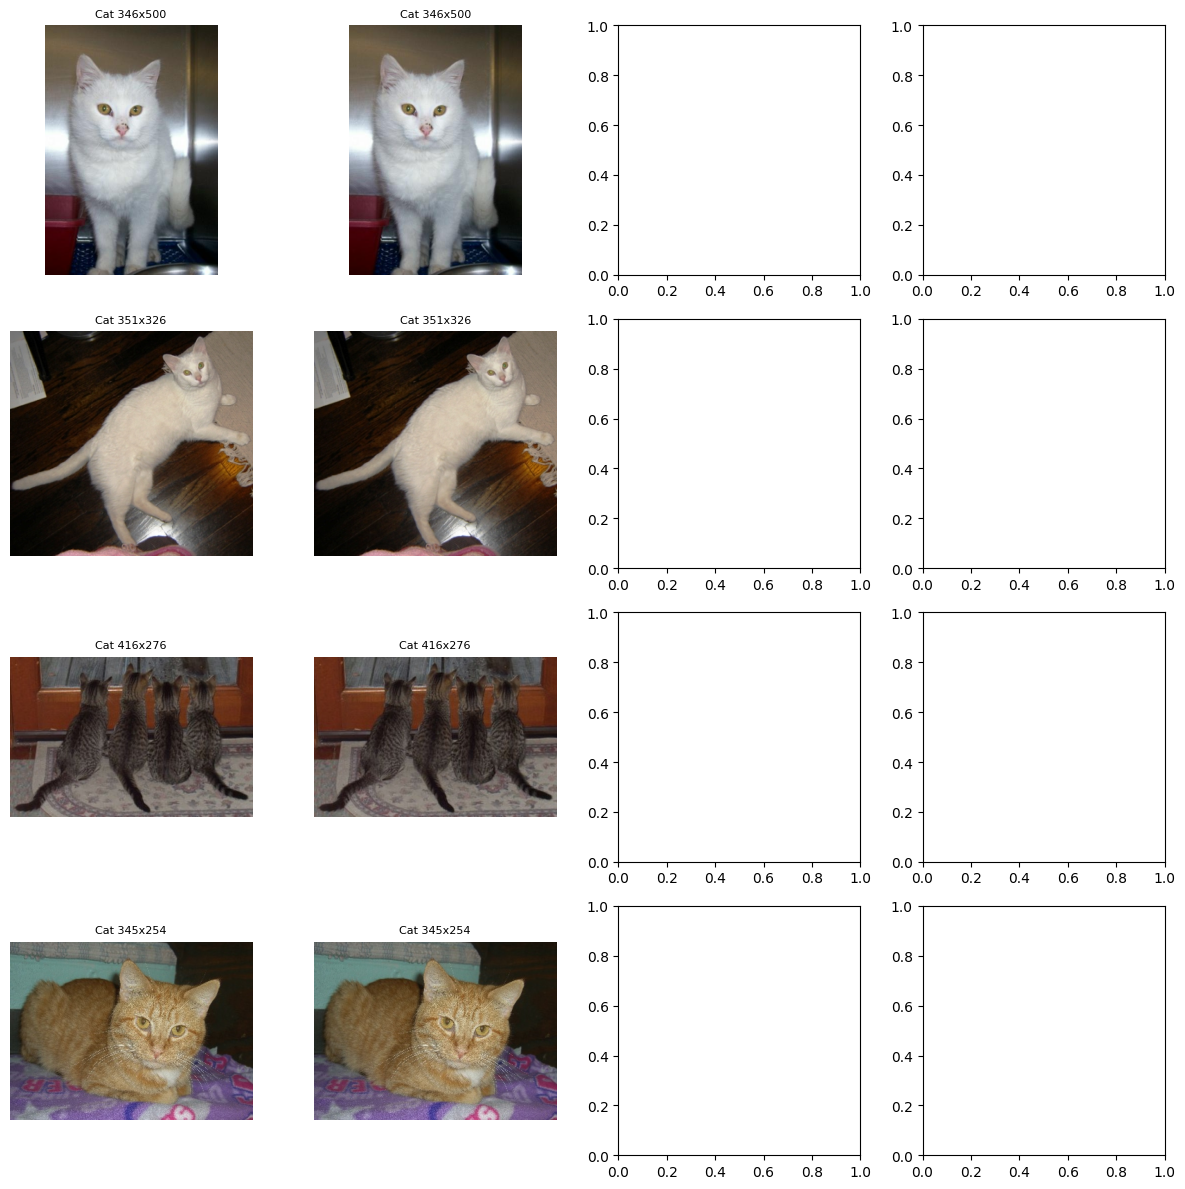

In [5]:
good = meta[meta["decode_ok"]].reset_index(drop=True)

# (a) exact duplicates: byte-identical files
exact_sizes = good.groupby("md5")["path"].transform("size")
print("Exact-duplicate files (in a group of 2+):", (exact_sizes > 1).sum(),
      "| extra copies:", (good.duplicated("md5")).sum())
cross = good.groupby("md5")["label"].nunique()
print("Exact-duplicate groups with BOTH labels (label conflict):", (cross > 1).sum())

# (b) near duplicates: perceptual hash within 4 of 64 bits
t0 = time.time()
pairs = data_processing.near_duplicate_pairs(good["phash"].tolist(), max_distance=4)
good["group_id"] = data_processing.group_ids_from_pairs(len(good), pairs)
gsize = good.groupby("group_id")["path"].transform("size")
print(f"\nNear-duplicate pairs: {len(pairs)} (computed in {time.time()-t0:.0f}s)")
print("Images in a near-duplicate group:", (gsize > 1).sum(),
      "| groups:", good.loc[gsize > 1, "group_id"].nunique(),
      "| largest group:", gsize.max())
near_cross = good.groupby("group_id")["label"].nunique()
print("Near-duplicate groups with BOTH labels:", (near_cross > 1).sum())

# visual check of the first few duplicate groups
multi = good[gsize > 1].groupby("group_id")
shown = 0
fig, axes = plt.subplots(4, 4, figsize=(12, 12))
for _, g in multi:
    if shown >= 4: break
    for ax, (_, row) in zip(axes[shown], g.head(4).iterrows()):
        with Image.open(row["path"]) as im: ax.imshow(im.convert("RGB"))
        ax.set_title(f"{row['label']} {row['width']}x{row['height']}", fontsize=8); ax.axis("off")
    shown += 1
plt.tight_layout(); plt.savefig(PROJECT_ROOT / "results/figures/03_duplicate_groups.png", dpi=110); plt.show()

min side < 16 / 32 / 64 px: [1, 1, 43]
extreme aspect > 2.5 / 3 / 4: [33, 5, 1]
file size < 1 KB / 2 KB: [3, 52] | > 500 KB: 21
near-uniform (32x32 gray std) < 2 / 5: [1, 1]


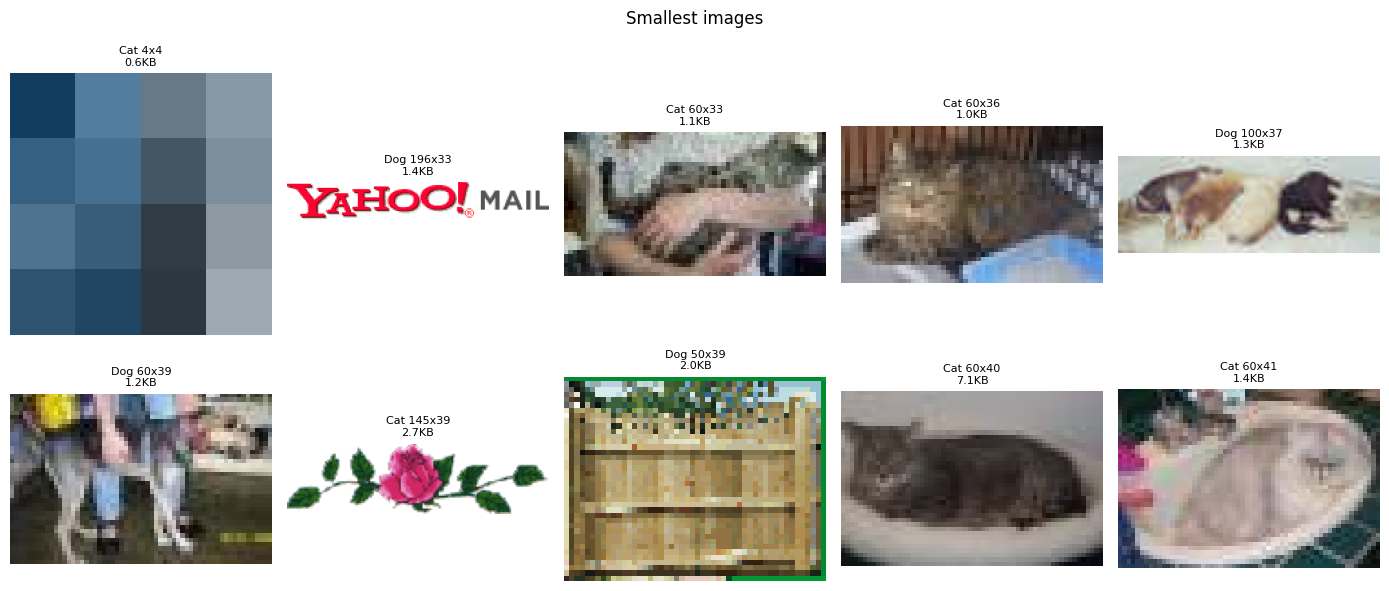

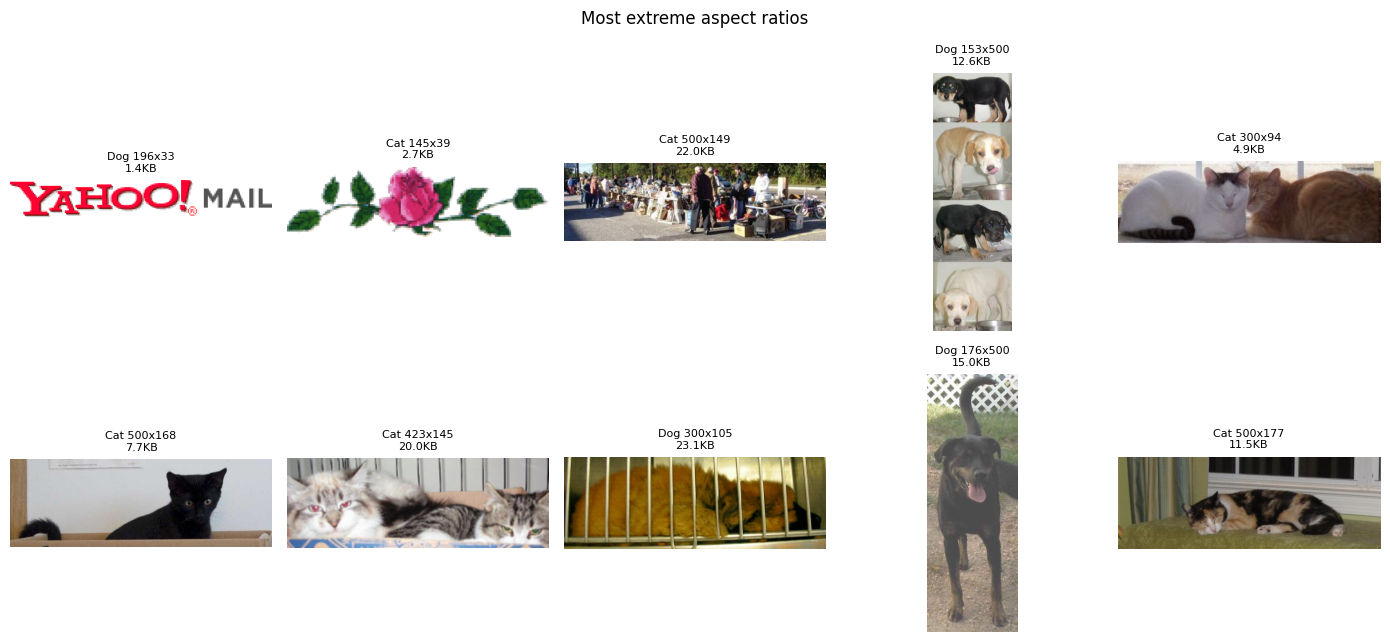

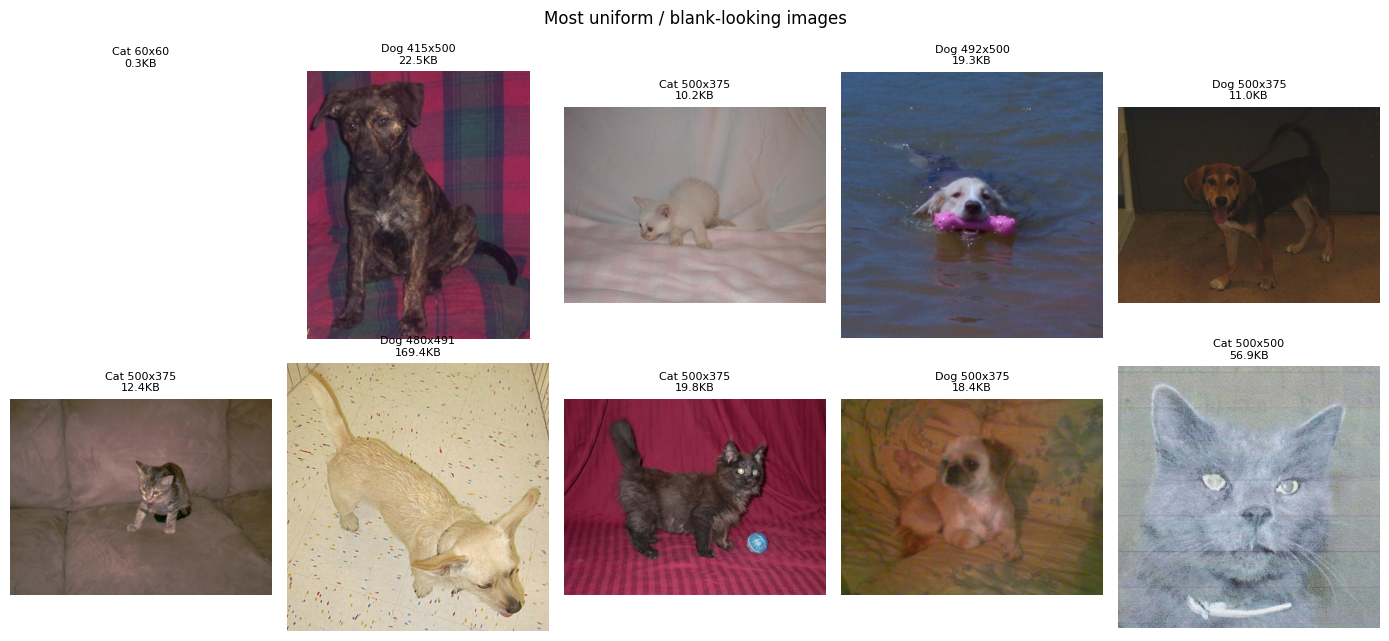

In [6]:
good["min_side"] = good[["width", "height"]].min(axis=1)
good["aspect_ext"] = np.maximum(good["width"] / good["height"], good["height"] / good["width"])

print("min side < 16 / 32 / 64 px:", [(good["min_side"] < t).sum() for t in (16, 32, 64)])
print("extreme aspect > 2.5 / 3 / 4:", [(good["aspect_ext"] > t).sum() for t in (2.5, 3, 4)])
print("file size < 1 KB / 2 KB:", [(good["file_size_kb"] < t).sum() for t in (1, 2)], "| > 500 KB:", (good["file_size_kb"] > 500).sum())
print("near-uniform (32x32 gray std) < 2 / 5:", [(good["thumb_std"] < t).sum() for t in (2, 5)])

def montage(df_, title, n=10):
    sub = df_.head(n)
    fig, axes = plt.subplots(2, 5, figsize=(14, 6.5))
    for ax in axes.ravel(): ax.axis("off")
    for ax, (_, r) in zip(axes.ravel(), sub.iterrows()):
        with Image.open(r["path"]) as im: ax.imshow(im.convert("RGB"))
        ax.set_title(f"{r['label']} {r['width']}x{r['height']}\n{r['file_size_kb']:.1f}KB", fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

montage(good.sort_values("min_side"), "Smallest images")
montage(good.sort_values("aspect_ext", ascending=False), "Most extreme aspect ratios")
montage(good.sort_values("thumb_std"), "Most uniform / blank-looking images")

In [7]:
print(pd.crosstab(good["mode"], good["pil_format"]))

pil_format  BMP  GIF   JPEG  PNG  PSD
mode                                 
CMYK          0    0      3    0    0
L             0    0      5    0    0
P             5   51      0    1    0
RGB         168    0  24761    1    1
RGBA          0    0      0    2    0


In [8]:
MIN_SIDE = 32          # drop images with a side shorter than this (judgement call: check against Cell 6)
MIN_THUMB_STD = 2.0    # drop near-uniform (blank-looking) images

log = []

# 1) Files that failed the full decode (these are not in `good`)
for p, e in zip(bad["path"], bad["decode_error"]):
    log.append({"path": p, "reason": f"corrupted: {e}"})

# 2) Rules applied to the readable images. Each helper only logs files not already excluded.
def drop(mask, reason):
    already = {r["path"] for r in log}
    for p in good.loc[mask, "path"]:
        if p not in already:
            log.append({"path": p, "reason": reason})

conflict_md5 = cross[cross > 1].index        # byte-identical files that carry BOTH labels
drop(good["md5"].isin(conflict_md5), "exact duplicate with conflicting labels")
drop(good["min_side"] < MIN_SIDE, f"tiny image (min side < {MIN_SIDE})")
drop(good["thumb_std"] < MIN_THUMB_STD, "near-uniform image")
drop(good.duplicated("md5", keep="first"), "exact duplicate (extra copy)")

cleaning_log = pd.DataFrame(log, columns=["path", "reason"]).drop_duplicates("path")
cleaning_log.to_csv(PROJECT_ROOT / "data/metadata/cleaning_log.csv", index=False)

clean = good[~good["path"].isin(cleaning_log["path"])].copy()
clean["label_id"] = clean["label"].map({"Cat": 0, "Dog": 1})
keep_cols = ["path", "label", "label_id", "width", "height", "mode",
             "pil_format", "md5", "phash", "group_id"]
clean[keep_cols].to_csv(PROJECT_ROOT / "data/metadata/metadata_clean.csv", index=False)

print("Original:", len(meta), "| excluded:", len(cleaning_log), "| remaining:", len(clean))
print("\nExclusion reasons:")
print(cleaning_log["reason"].str.split(":").str[0].value_counts())
print("\nClass balance after cleaning:")
print(clean["label"].value_counts())
print(clean["label"].value_counts(normalize=True).round(4))

Original: 24998 | excluded: 34 | remaining: 24964

Exclusion reasons:
reason
exact duplicate (extra copy)               26
exact duplicate with conflicting labels     6
tiny image (min side < 32)                  1
near-uniform image                          1
Name: count, dtype: int64

Class balance after cleaning:
label
Dog    12486
Cat    12478
Name: count, dtype: int64
label
Dog    0.5002
Cat    0.4998
Name: proportion, dtype: float64
